# Домашнее задание. Занятие 11. Мидтерм, этап 1: от сырого файла к чистой таблице

**DataGroup. Курс AI Engineering. Неделя 6**

Это тетрадь вашего мидтерм-проекта. На этапе 1 (домашка занятия 11) вы заполняете разделы 0-9: выбираете датасет и доводите его до чистой таблицы с EDA. На этапе 2 (домашка занятия 12, сам мидтерм) продолжаете **эту же тетрадь**, разделы 10-16: признаки, утечка, baseline и README. Полное ТЗ с критериями и списком датасетов в файле `Midterm_TZ.md`.

**Как работать с тетрадью**

1. Откройте её в Google Colab: «Файл», затем «Загрузить блокнот». Сразу переименуйте в `project.ipynb`: под этим именем она будет лежать в репозитории.
2. **Первой запустите ячейку «Помощники»** ниже. Если перезапустили среду, запустите её снова.
3. Идите по разделам сверху вниз. В каждом разделе есть **«Что сделать»**, ссылка на часть тетради практики занятия 11, где это показано на отелях, пустые ячейки для кода и ячейка **«Вывод»**: её заполняете своими словами.
4. Каждое решение про данные записывайте в журнал: `log("шаг", "что решили", len(df))`.
5. В конце этапа запустите самопроверку (раздел 9), потом «Среда выполнения», затем «Перезапустить сеанс и выполнить все»: тетрадь должна пройти без ошибок.
6. Загрузите тетрадь и файлы в публичный репозиторий на GitHub и сдайте **ссылку на репозиторий** в LMS. Как загрузить, в разделе 9 и в ТЗ.

**Баллы этапа 1: 100.**

| раздел | баллы |
|---|---|
| 0-1. Карточка проекта и первый взгляд | 10 |
| 2-3. Дубли и невозможные значения | 15 |
| 4. Пропуски | 20 |
| 5-6. Типы, даты и выбросы | 15 |
| 7. EDA: 5 графиков с выводами | 20 |
| 8. Функция `clean`, сторожа, журнал, чистый CSV | 10 |
| 9. Репозиторий: публичный, тетрадь с выводами | 10 |

**Данные.** Один датасет из списка в ТЗ или свой, согласованный в чате группы. Вот список коротко, ссылки и подробности в ТЗ:

| датасет | задача | уровень |
|---|---|---|
| клиенты телеком-компании (Telco) | классификация: уйдёт ли клиент | базовый |
| поездки на такси в Нью-Йорке | регрессия: чаевые или стоимость | базовый |
| рейтинги шоколада | регрессия: оценка плитки | базовый |
| банк: телемаркетинг вкладов | классификация: откроет ли вклад | средний |
| восхождения в Гималаях | классификация: дойдёт ли до вершины | средний |
| Airbnb в Нью-Йорке | регрессия: цена ночи | средний |
| песни Spotify | регрессия: популярность трека | средний |
| мебель IKEA | регрессия: цена | средний |
| оценки кофе | регрессия: итоговая оценка | продвинутый |
| дома в Эймсе | регрессия: цена дома | продвинутый |

**Как устроено.** Проверки с баллами здесь нет: работу проверяет преподаватель по критериям из ТЗ. Решения принимаете вы, и главное в каждом разделе не код, а **вывод**: что вы увидели и почему решили именно так. Короткий честный вывод лучше длинного пересказа кода.

**Чем пользоваться.** Помощники ниже: `load_csv`, `passport`, `log` и `show_journal`, `target_plot`, `selfcheck`. Всё остальное из тетради практики занятия 11: её функции можно копировать и менять под свои данные.

**Если застряли.** Каждый раздел ссылается на часть тетради практики, где то же самое сделано на отелях. Задайте вопрос в чате группы, не дожидаясь срока. И ставьте `print` после каждого шага: почти всегда окажется, что в таблице лежит не то, что вы думали.

---
## Помощники

Запустите эту ячейку первой. Она подключает библиотеки и создаёт пять функций для проекта.

In [ ]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("project_data")
DATA.mkdir(exist_ok=True)
TEAL, ORANGE, RED, NAVY, GRAY = "#278071", "#E0843B", "#B0413E", "#13293E", "#8A94A0"
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)


def load_csv(url, name="raw", **options):
    """Скачать CSV по ссылке один раз в папку project_data, дальше читать с диска."""
    path = DATA / f"{name}.csv"
    if not path.exists():
        urlretrieve(url, path)
    return pd.read_csv(path, **options)


def passport(table):
    """Паспорт данных: одна строка на столбец, тип, пропуски, разных значений, пример."""
    return pd.DataFrame({
        "тип": table.dtypes.astype(str),
        "пропусков": table.isna().sum(),
        "доля, %": (table.isna().mean() * 100).round(1),
        "разных": table.nunique(),
        "пример": table.iloc[0],
    })


journal = {}


def log(step, decision, rows):
    """Записать решение в журнал. Повторный запуск с тем же шагом перезаписывает запись."""
    journal[step] = {"решение": decision, "строк": rows}


def show_journal():
    """Журнал решений таблицей."""
    return pd.DataFrame(journal).T


def target_plot(table, groups, target, title, xlabel):
    """Цель по группам. Цель 0 и 1: доля единиц в процентах. Цель число: медиана."""
    is_class = set(table[target].dropna().unique()) <= {0, 1}
    stat = "mean" if is_class else "median"
    result = table.groupby(groups, observed=True)[target].agg([stat, "size"])
    values = result[stat] * 100 if is_class else result[stat]
    overall = table[target].mean() * 100 if is_class else table[target].median()
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    bars = ax.bar(result.index.astype(str), values, color=TEAL)
    ax.axhline(overall, color=ORANGE, ls="--", label="по всем данным")
    labels = ax.bar_label(bars, fmt="%.0f%%" if is_class else "%.1f", padding=2)
    for label in labels:
        label.set_bbox({"facecolor": "white", "edgecolor": "none", "pad": 1})
    ax.set_ylim(0, max(values.max(), overall) * 1.4)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(f"доля {target} = 1, %" if is_class else f"медиана {target}")
    ax.legend(loc="best")
    if len(result) > 6 or max(len(str(i)) for i in result.index) > 12:
        plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()
    return result.round(3)


def selfcheck(raw_table, clean_table, target):
    """Самопроверка этапа 1: что готово, а что нет."""
    has_target = target in clean_table.columns
    checks = [
        ("цель есть в чистой таблице", has_target),
        ("цель без пропусков", has_target and bool(clean_table[target].notna().all())),
        ("цель числом: класс 0 и 1 или число", has_target and pd.api.types.is_numeric_dtype(clean_table[target])),
        ("в чистой таблице нет пропусков", int(clean_table.isna().sum().sum()) == 0),
        ("полных дублей нет (если есть, объясните в выводе)", not clean_table.duplicated().any()),
        ("осталось больше половины строк", len(clean_table) > len(raw_table) / 2),
        ("в журнале минимум 5 решений", len(journal) >= 5),
    ]
    for name, ok in checks:
        print(("OK   " if ok else "НЕТ  ") + name)
    print(f"строк: было {len(raw_table)}, стало {len(clean_table)}; столбцов: было {raw_table.shape[1]}, стало {clean_table.shape[1]}")


print("помощники готовы")

помощники готовы


---
# Этап 1. Домашка занятия 11

---
## 0. Карточка проекта  ·  вместе с разделом 1: 10 баллов

**Что сделать.** Заполните таблицу ниже (двойной щелчок по ячейке) и укажите ссылку и цель в коде. Пример карточки: часть 1 тетради практики, раздел 1.1.

| вопрос | ответ |
|---|---|
| датасет и ссылка на источник | Telco Customer Churn — https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv |
| что значит одна строка | Один клиент телеком-компании |
| цель (столбец) | Churn — ушёл клиент (1) или остался (0) |
| тип задачи | Классификация |
| метрика | Доля верных ответов  |
| кому и зачем нужен такой прогноз | Телеком-компании для выявления клиентов с риском ухода |

In [ ]:
DATA_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv" # прямая ссылка на CSV из ТЗ или на свой файл
TARGET = "Churn"     # имя столбца-цели

---
## 1. Первый взгляд

**Что сделать.**

* загрузить данные: `raw = load_csv(DATA_URL)`, посмотреть `shape` и `head`;
* паспорт данных: `passport(raw)`;
* распределение цели: для класса `value_counts()`, для числа `describe()` и гистограмма;
* если цель текстом («Yes» и «No»), превратить её в 0 и 1, например `(raw[TARGET] == "Yes").astype(int)`, и записать это в журнал.

Пример: часть 1 практики, разделы 1.1-1.4.

In [ ]:
raw = load_csv(DATA_URL)

print("Размер таблицы:", raw.shape)

display(raw.head())

# загрузка, shape, head

Размер таблицы: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
passport(raw)

# паспорт данных

,тип,пропусков,"доля, %",разных,пример
customerID,object,0,0.0,7043,7590-VHVEG
gender,object,0,0.0,2,Female
SeniorCitizen,int64,0,0.0,2,0
Partner,object,0,0.0,2,Yes
Dependents,object,0,0.0,2,No
tenure,int64,0,0.0,73,1
PhoneService,object,0,0.0,2,No
MultipleLines,object,0,0.0,3,No phone service
InternetService,object,0,0.0,3,DSL
OnlineSecurity,object,0,0.0,3,No


In [ ]:
print("Распределение цели до преобразования:")
print(raw[TARGET].value_counts())

if not pd.api.types.is_numeric_dtype(raw[TARGET]):
    raw[TARGET] = raw[TARGET].map({"Yes": 1, "No": 0})

assert raw[TARGET].notna().all()

print("\nРаспределение цели после преобразования:")
print(raw[TARGET].value_counts())

print("\nДоли классов:")
print(raw[TARGET].value_counts(normalize=True) * 100)

# цель: распределение, при необходимости в числа 0 и 1

Распределение цели до преобразования:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Распределение цели после преобразования:
Churn
0    5174
1    1869
Name: count, dtype: int64

Доли классов:
Churn
0    73.463013
1    26.536987
Name: proportion, dtype: float64


**Вывод.** Датасет содержит 7 043 строки и 21 столбец. Каждая строка описывает одного клиента телеком-компании. Целевой признак Churn преобразован из Yes/No в 1/0.

По результатам анализа 5 174 клиента (73,46%) остались в компании, а 1 869 клиентов (26,54%) ушли. Классы распределены неравномерно, поэтому в дальнейшем необходимо сравнивать качество модели с baseline.

Столбец TotalCharges имеет текстовый тип данных, хотя содержит суммы платежей. Это требует дополнительной проверки и преобразования в числовой формат.

---
## 2. Дубли  ·  вместе с разделом 3: 15 баллов

**Что сделать.**

* сколько полных дублей: `raw.duplicated().sum()`;
* если в данных есть номер записи (id), то и повторы по нему: `duplicated(subset=["..."])`;
* посмотреть на несколько дублей глазами (`keep=False`) и решить, что это: ошибка выгрузки, одна запись в нескольких местах или разные настоящие строки;
* записать решение в журнал.

Пример: часть 2 практики, разделы 2.1-2.4.

In [ ]:
print("Полных дублей:", raw.duplicated().sum())

print("Повторов customerID:",
      raw.duplicated(subset=["customerID"]).sum())

display(raw[raw.duplicated(keep=False)].head())

display(raw[raw.duplicated(
    subset=["customerID"], keep=False
)].head())

# сколько дублей, какие они

Полных дублей: 0
Повторов customerID: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


In [ ]:
df = raw.drop_duplicates().copy()

log(
    "Дубли",
    "Удаляем только полные дубли строк, если они есть",
    len(df)
)

print("Было строк:", len(raw))
print("Стало строк:", len(df))

# решение: df = ... ; log(...)

Было строк: 7043
Стало строк: 7043


**Вывод.** В датасете не обнаружено полных дублей строк и повторяющихся идентификаторов customerID. Каждый идентификатор соответствует отдельному клиенту.

Удаление строк не требуется, поскольку повторяющихся записей нет. После проверки количество строк осталось неизменным — 7 043.

---
## 3. Невозможные значения и скрытые пропуски

**Что сделать.**

* написать функцию `check_rules(d)`, которая возвращает таблицу флагов: минимум 3 правила здравого смысла (отрицательная цена, ноль там, где ноль невозможен, возраст 150 лет);
* посмотреть на нарушителей глазами и решить по каждому правилу: удалить, исправить или оставить;
* найти скрытые пропуски: `value_counts()` по текстовым столбцам, `describe()` по числовым. Ищите `unknown`, `Undefined`, `?`, пробел, `999`, нули там, где их не бывает;
* записать решения в журнал.

Пример: часть 2 практики, разделы 2.5-2.7.

In [ ]:
def check_rules(d):
    """Проверка невозможных значений."""

    return pd.DataFrame({
        "Отрицательный стаж": d["tenure"] < 0,
        "Отрицательный платеж": d["MonthlyCharges"] < 0,
        "Некорректный SeniorCitizen": ~d["SeniorCitizen"].isin([0, 1]),
        "Стаж больше 72 месяцев": d["tenure"] > 72
    }, index=d.index)

In [ ]:
rules = check_rules(df)

print("Количество нарушений:")
print(rules.sum())

print("\nСтроки с нарушениями:")
display(df.loc[rules.any(axis=1)].head(10))

# сколько нарушений по каждому правилу, нарушители глазами

Количество нарушений:
Отрицательный стаж            0
Отрицательный платеж          0
Некорректный SeniorCitizen    0
Стаж больше 72 месяцев        0
dtype: int64

Строки с нарушениями:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


In [ ]:
print("Распределение TotalCharges:")
print(df["TotalCharges"].value_counts().head(15))

print("\nПустые строки в TotalCharges:")
print((df["TotalCharges"].str.strip() == "").sum())

print("\nПроверка категорий:")
for col in ["InternetService", "OnlineSecurity", "Contract"]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))

print("\nЧисловые признаки:")
display(df[["tenure", "MonthlyCharges"]].describe())

# скрытые пропуски: value_counts и describe

Распределение TotalCharges:
TotalCharges
         11
20.2     11
19.75     9
20.05     8
19.9      8
19.65     8
19.55     7
45.3      7
20.15     6
20.25     6
19.45     6
20.3      5
20.45     5
74.7      4
20.5      4
Name: count, dtype: int64

Пустые строки в TotalCharges:
11

Проверка категорий:

InternetService:
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity:
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

Contract:
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

Числовые признаки:


,tenure,MonthlyCharges
count,7043.000000,7043.000000
mean,32.371149,64.761692
std,24.559481,30.090047
min,0.000000,18.250000
25%,9.000000,35.500000
50%,29.000000,70.350000
75%,55.000000,89.850000
max,72.000000,118.750000


In [ ]:
violations = check_rules(df)

print("Всего строк с нарушениями:",
      violations.any(axis=1).sum())

if violations.any(axis=1).sum() == 0:
    log(
        "Невозможные значения",
        "Нарушений проверенных правил нет. Строки сохранены.",
        len(df)
    )
else:
    print("Есть нарушения. Требуется проверить их перед исправлением.")

# решения и журнал

Всего строк с нарушениями: 0


**Вывод.** Проверены четыре правила: отрицательный стаж клиента, отрицательная сумма ежемесячного платежа, некорректные значения SeniorCitizen и стаж более 72 месяцев. Нарушений не обнаружено, поэтому удалять строки не требуется.

При анализе TotalCharges найдено 11 скрытых пропусков, записанных как пробелы. Из-за этого столбец имеет текстовый тип данных. Пропуски необходимо дополнительно изучить и обработать.

Значение No internet service в категориальных признаках означает отсутствие интернет-услуги, а не неизвестное значение, поэтому его сохраняем.

---
## 4. Пропуски  ·  20 баллов

**Что сделать.**

* для каждого столбца с пропусками сравнить цель у строк с пропуском и без: `df.groupby(df[col].isna())[TARGET].mean()`;
* решить, что значит пропуск: «не знаем» или «нет»;
* заполнить: «нет» по смыслу (0, «нет»), «не знаем» медианой, самым частым или категорией `Unknown`; если пропуск говорит о строке, сначала флаг; если пропусков больше половины, флаг и удалить столбец;
* заполнить таблицу решений ниже и записать решения в журнал.

По желанию, без баллов: проверить способ заполнения на известных значениях, как в разделе 3.4 практики.

Пример: часть 3 практики.

In [ ]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].str.strip(),
    errors="coerce"
)

print("Пропуски по столбцам:")
print(df.isna().sum()[df.isna().sum() > 0])

print("\nКлиенты с пропусками TotalCharges:")
display(df.loc[df["TotalCharges"].isna(),
               ["customerID", "tenure", "MonthlyCharges",
                "TotalCharges", "Churn"]])

# где пропуски и сколько

Пропуски по столбцам:
TotalCharges    11
dtype: int64

Клиенты с пропусками TotalCharges:


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,0
753,3115-CZMZD,0,20.25,NaN,0
936,5709-LVOEQ,0,80.85,NaN,0
1082,4367-NUYAO,0,25.75,NaN,0
1340,1371-DWPAZ,0,56.05,NaN,0
3331,7644-OMVMY,0,19.85,NaN,0
3826,3213-VVOLG,0,25.35,NaN,0
4380,2520-SGTTA,0,20.00,NaN,0
5218,2923-ARZLG,0,19.70,NaN,0
6670,4075-WKNIU,0,73.35,NaN,0


In [ ]:
missing = df["TotalCharges"].isna()

print("Связь пропусков с уходом клиентов:")
display(df.groupby(missing)["Churn"].agg(["count", "mean"]))

print("\nСтаж клиентов с пропусками:")
print(df.loc[missing, "tenure"].value_counts())

print("\nУ всех клиентов с пропусками стаж 0?")
print(df.loc[missing, "tenure"].eq(0).all())

# пропуск как информация: цель у строк с пропуском и без

Связь пропусков с уходом клиентов:


,count,mean
TotalCharges,,
False,7032,0.265785
True,11,0.000000



Стаж клиентов с пропусками:
tenure
0    11
Name: count, dtype: int64

У всех клиентов с пропусками стаж 0?
True


In [ ]:
missing = df["TotalCharges"].isna()

assert df.loc[missing, "tenure"].eq(0).all(), \
    "Есть пропуски у клиентов со стажем больше нуля!"

df["TotalCharges_missing"] = missing.astype(int)

df["TotalCharges"] = df["TotalCharges"].fillna(0)

log(
    "Пропуски",
    "11 пустых TotalCharges: флаг пропуска и заполнение нулём для новых клиентов",
    len(df)
)

print("Осталось пропусков:", df.isna().sum().sum())
print("Размер таблицы:", df.shape)

# заполнение и журнал

Осталось пропусков: 0
Размер таблицы: (7043, 22)


| столбец | пропусков | «не знаем» или «нет» | что делаем | почему |
|---|---|---|---|---|
| TotalCharges | 11 | Нет накопленных платежей | Заполнить 0, создать флаг TotalCharges_missing | У всех 11 клиентов tenure = 0 |


**Вывод.** В столбце TotalCharges обнаружено 11 скрытых пропусков, записанных как пробелы.

Проверка показала, что все эти клиенты имеют нулевой стаж обслуживания. Поэтому пропуски заменены на 0, а информация об их первоначальном наличии сохранена в новом признаке TotalCharges_missing.

После обработки пропусков не осталось. Количество строк сохранилось — 7 043, количество столбцов увеличилось до 22.

---
## 5. Типы и даты  ·  вместе с разделом 6: 15 баллов

**Что сделать.**

* числа, записанные текстом, превратить в числа: `pd.to_numeric(s, errors="coerce")`, и посмотреть, что попало в пропуски;
* текст с единицами («76%», «SR 1,385», «1800-2200») разобрать: `str.replace`, `str.extract`;
* даты превратить в даты: `pd.to_datetime`, и достать из них признаки: месяц, день недели, час, разницу дат;
* показать `dtypes` после исправлений.

Если в ваших данных нет ни дат, ни чисел текстом, напишите это в выводе: так тоже бывает.

Пример: часть 4 практики, разделы 4.1-4.3.

In [ ]:
# Проверяем числовые столбцы после исправления

numeric_cols = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "Churn",
    "TotalCharges_missing"
]

print("Типы числовых столбцов:")
print(df[numeric_cols].dtypes)

print("\nТипы всех столбцов:")
display(df.dtypes.to_frame(name="Тип данных"))

# Проверяем исправленный столбец
assert pd.api.types.is_numeric_dtype(df["TotalCharges"])
assert df["TotalCharges"].notna().all()

log(
    "Типы данных",
    "TotalCharges преобразован из текста в число. Категории оставлены текстовыми.",
    len(df)
)

print("\nПроверка типов пройдена")

# числа текстом

Типы числовых столбцов:
SeniorCitizen             int64
tenure                    int64
MonthlyCharges          float64
TotalCharges            float64
Churn                     int64
TotalCharges_missing      int64
dtype: object

Типы всех столбцов:


,Тип данных
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object



Проверка типов пройдена


In [ ]:
# Проверка столбцов с датами

date_cols = df.select_dtypes(
    include=["datetime", "datetimetz"]
).columns.tolist()

print("Столбцы с датами:", date_cols)

print(
    "В исходном датасете Telco отсутствуют даты. "
    "Преобразование дат не требуется."
)

log(
    "Даты",
    "Даты отсутствуют, преобразование не требуется.",
    len(df)
)

# даты

Столбцы с датами: []
В исходном датасете Telco отсутствуют даты. Преобразование дат не требуется.


**Вывод.** Столбец TotalCharges изначально имел текстовый тип object, хотя содержал числовые значения. В разделе 4 он преобразован в числовой формат с помощью pd.to_numeric().

Остальные числовые столбцы уже имели корректные типы. Категориальные признаки сохранены как текстовые, их кодирование будет выполнено на втором этапе проекта.

В датасете отсутствуют столбцы с датами, поэтому их преобразование и создание временных признаков не требуются.

---
## 6. Выбросы

**Что сделать.**

* для главных числовых столбцов найти кандидатов в выбросы: граница IQR или процентили (`quantile(0.999)`);
* по каждому решить: ошибка (удалить или исправить) или редкость (оставить, обрезать `clip`, сжать `np.log1p`);
* для длинного хвоста показать гистограммы до и после логарифма;
* записать решения в журнал.

Пример: часть 4 практики, разделы 4.4-4.6.

In [ ]:
# Проверяем основные числовые признаки методом IQR

numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

results = []

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = (df[col] < lower) | (df[col] > upper)

    results.append({
        "Столбец": col,
        "Минимум": df[col].min(),
        "Максимум": df[col].max(),
        "Нижняя граница": round(lower, 2),
        "Верхняя граница": round(upper, 2),
        "Выбросов": int(outliers.sum())
    })

iqr_table = pd.DataFrame(results)

display(iqr_table)

# кандидаты в выбросы

,Столбец,Минимум,Максимум,Нижняя граница,Верхняя граница,Выбросов
0,tenure,0.00,72.00,-60.00,124.00,0
1,MonthlyCharges,18.25,118.75,-46.02,171.38,0
2,TotalCharges,0.00,8684.80,-4683.52,8868.67,0


Пять клиентов с самыми большими TotalCharges:


,tenure,MonthlyCharges,TotalCharges,Churn
4610,72,117.80,8684.80,1
4586,72,118.75,8672.45,0
6768,72,117.50,8670.10,0
5347,72,116.95,8594.40,0
2187,71,116.25,8564.75,0


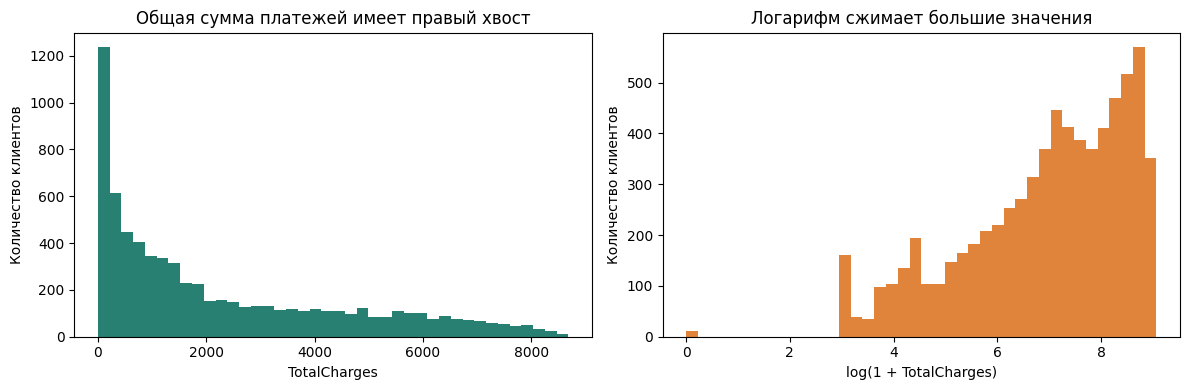

Строк после проверки: 7043


In [ ]:
# Проверяем крайние значения платежей

print("Пять клиентов с самыми большими TotalCharges:")

display(
    df.nlargest(5, "TotalCharges")[
        ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

# Сравниваем распределение до и после логарифма

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["TotalCharges"], bins=40, color=TEAL)
axes[0].set_title("Общая сумма платежей имеет правый хвост")
axes[0].set_xlabel("TotalCharges")
axes[0].set_ylabel("Количество клиентов")

axes[1].hist(np.log1p(df["TotalCharges"]), bins=40, color=ORANGE)
axes[1].set_title("Логарифм сжимает большие значения")
axes[1].set_xlabel("log(1 + TotalCharges)")
axes[1].set_ylabel("Количество клиентов")

plt.tight_layout()
plt.show()

# Не удаляем и не обрезаем значения автоматически

assert (df["tenure"] >= 0).all()
assert (df["MonthlyCharges"] >= 0).all()
assert (df["TotalCharges"] >= 0).all()

log(
    "Выбросы",
    "Проверены tenure, MonthlyCharges и TotalCharges методом IQR. "
    "Крайние значения сохраняем, логарифм рассмотрен для TotalCharges.",
    len(df)
)

print("Строк после проверки:", len(df))

# решения: удалить, обрезать, логарифм

**Вывод.** Методом IQR проверены три числовых признака: tenure, MonthlyCharges и TotalCharges. Значений за рассчитанными границами не обнаружено.

Максимальный стаж составляет 72 месяца, ежемесячный платёж — 118,75, общая сумма платежей — 8 684,80.

Наибольшие значения TotalCharges наблюдаются у клиентов с длительным сроком обслуживания и высокими ежемесячными платежами. Поэтому они выглядят правдоподобными.

Для TotalCharges дополнительно рассмотрено логарифмическое преобразование, которое сжимает большие значения и помогает анализировать распределение.

Удаление, обрезка и изменение значений не требуются. Все 7 043 строки сохранены.

---
## 7. EDA: пять графиков  ·  20 баллов

**Что сделать.** Минимум 5 графиков. У каждого заголовок-вывод (не «lead_time и is_canceled», а «Чем раньше бронь, тем чаще отмена»), подписи осей с единицами и 1-3 предложения под графиком.

| график | на какой вопрос отвечает |
|---|---|
| распределение цели | какая доля классов или как распределено число |
| цель по 3-4 сильным признакам | что сильнее всего связано с целью |
| цель по времени или по группам | меняется ли картина по сезонам, городам, категориям |
| находка | что удивило: парадокс или подозрительно идеальный признак |

`target_plot(df, группы, TARGET, "заголовок-вывод", "подпись оси x")` рисует цель по группам. Числовой признак сначала разбейте на интервалы: `pd.cut(df["столбец"], [границы])`. Для двух числовых столбцов подойдёт `plt.scatter`.

Пример: часть 6 практики.

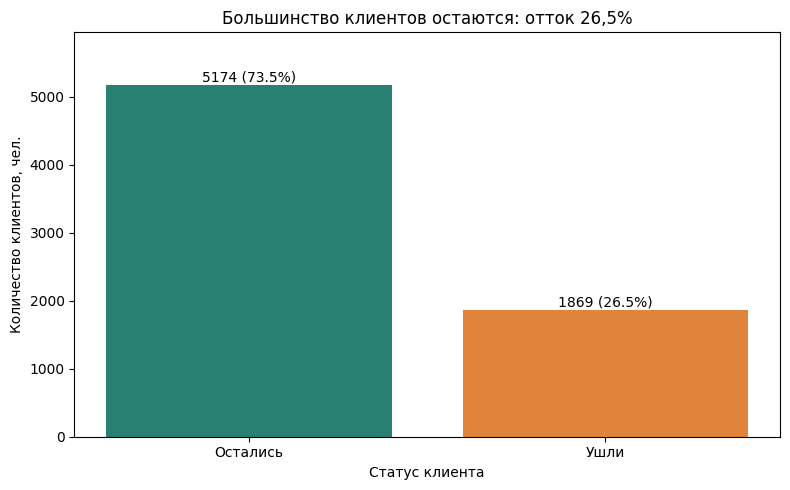

In [ ]:
# График 1. Распределение клиентов

counts = df["Churn"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["Остались", "Ушли"],
    counts.values,
    color=[TEAL, ORANGE]
)

for bar, count in zip(bars, counts.values):
    percent = count / len(df) * 100
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 50,
        f"{count} ({percent:.1f}%)",
        ha="center"
    )

plt.title("Большинство клиентов остаются: отток 26,5%")
plt.xlabel("Статус клиента")
plt.ylabel("Количество клиентов, чел.")
plt.ylim(0, counts.max() * 1.15)

plt.tight_layout()
plt.show()

**Что видно на графике 1.** Из 7 043 клиентов компанию покинули 1 869 человек (26,54%), а 5 174 (73,46%) остались.

Количество оставшихся клиентов значительно превышает количество ушедших. Такое распределение необходимо учитывать при дальнейшем обучении и оценке модели.

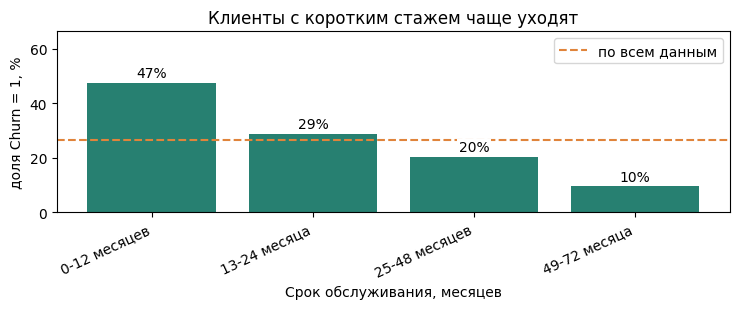

Доля ухода и количество клиентов:


,mean,size
tenure,,
0-12 месяцев,0.474,2186
13-24 месяца,0.287,1024
25-48 месяцев,0.204,1594
49-72 месяца,0.095,2239


In [ ]:
# График 2. Уход клиентов по сроку обслуживания

tenure_groups = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "0-12 месяцев",
        "13-24 месяца",
        "25-48 месяцев",
        "49-72 месяца"
    ]
)

result = target_plot(
    df,
    tenure_groups,
    TARGET,
    "Клиенты с коротким стажем чаще уходят",
    "Срок обслуживания, месяцев"
)

print("Доля ухода и количество клиентов:")
display(result)

**Что видно на графике 2.** Самая высокая доля ухода наблюдается среди клиентов со стажем до 12 месяцев — 47,4%. Среди клиентов со стажем от 49 до 72 месяцев она составляет только 9,5%.

Таким образом, чем дольше клиент пользуется услугами компании, тем ниже наблюдаемая доля оттока. Это не доказывает причинно-следственную связь, но показывает, что стаж может быть полезным признаком для прогнозирования.

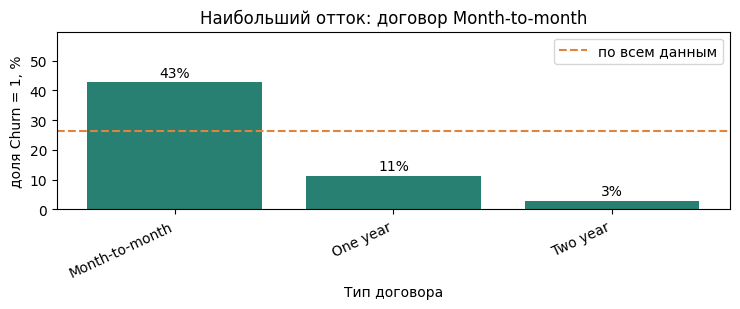

,Клиентов,"Отток, %"
Contract,,
Month-to-month,3875,42.7
One year,1473,11.3
Two year,1695,2.8


In [ ]:
# График 3. Отток по типу договора

contract_rates = df.groupby("Contract")["Churn"].mean()
highest_contract = contract_rates.idxmax()

result3 = target_plot(
    df,
    df["Contract"],
    TARGET,
    f"Наибольший отток: договор {highest_contract}",
    "Тип договора"
)

display(pd.DataFrame({
    "Клиентов": result3["size"],
    "Отток, %": (result3["mean"] * 100).round(1)
}))

**Что видно на графике 3.** Самая высокая доля ухода наблюдается среди клиентов с помесячным договором — 42,7%. Среди клиентов с годовым договором она составляет 11,3%, а с двухлетним — всего 2,8%.

Клиенты с долгосрочными договорами значительно реже покидают компанию. Тип договора может быть важным признаком для прогнозирования оттока.

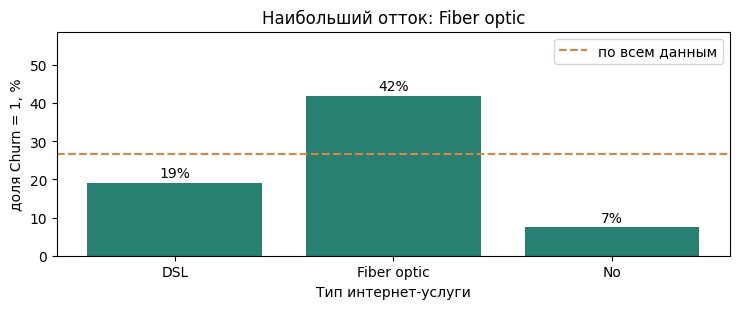

,Клиентов,"Отток, %"
InternetService,,
DSL,2421,19.0
Fiber optic,3096,41.9
No,1526,7.4


In [ ]:
# График 4. Отток по типу интернета

internet_rates = df.groupby("InternetService")["Churn"].mean()
highest_internet = internet_rates.idxmax()

result4 = target_plot(
    df,
    df["InternetService"],
    TARGET,
    f"Наибольший отток: {highest_internet}",
    "Тип интернет-услуги"
)

display(pd.DataFrame({
    "Клиентов": result4["size"],
    "Отток, %": (result4["mean"] * 100).round(1)
}))

**Что видно на графике 4.** Наибольшая доля ухода наблюдается среди клиентов с оптоволоконным интернетом Fiber optic — 41,9%.

Среди пользователей DSL доля ухода составляет 19,0%, а среди клиентов без интернет-услуг — 7,4%.

Тип интернет-услуги связан с вероятностью ухода клиента. Однако по этим данным нельзя утверждать, что именно технология подключения является причиной оттока.

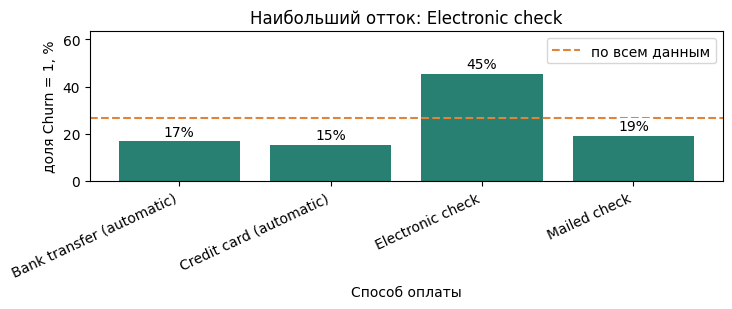

,Клиентов,"Отток, %"
PaymentMethod,,
Bank transfer (automatic),1544,16.7
Credit card (automatic),1522,15.2
Electronic check,2365,45.3
Mailed check,1612,19.1


In [ ]:
# График 5. Отток по способу оплаты

payment_rates = df.groupby("PaymentMethod")["Churn"].mean()
highest_payment = payment_rates.idxmax()

result5 = target_plot(
    df,
    df["PaymentMethod"],
    TARGET,
    f"Наибольший отток: {highest_payment}",
    "Способ оплаты"
)

display(pd.DataFrame({
    "Клиентов": result5["size"],
    "Отток, %": (result5["mean"] * 100).round(1)
}))

**Что видно на графике 5.** Наибольшая доля ухода наблюдается среди клиентов со способом оплаты Electronic check — 45,3%.

При автоматической оплате банковским переводом доля ухода составляет 16,7%, а банковской картой — 15,2%.

Таким образом, способ оплаты связан с оттоком клиентов. Клиенты с автоматическими платежами реже уходят, но причинную связь необходимо исследовать отдельно.

**Вывод по EDA.**

1. Общая доля ухода клиентов составляет 26,54%. Большинство клиентов (73,46%) продолжают пользоваться услугами компании.

2. Стаж обслуживания связан с оттоком. Среди клиентов со стажем до 12 месяцев доля ухода составляет 47,4%, а среди клиентов со стажем 49–72 месяца — 9,5%.

3. Тип договора имеет выраженную связь с оттоком: при помесячном договоре уходят 42,7% клиентов, а при двухлетнем — 2,8%.

4. Среди клиентов с интернетом Fiber optic доля ухода составляет 41,9%, что выше, чем среди пользователей DSL (19,0%).

5. Клиенты, использующие Electronic check, уходят чаще (45,3%), чем клиенты с автоматической оплатой банковской картой (15,2%).

Итог. Наиболее интересными признаками для дальнейшего прогнозирования являются стаж клиента, тип договора, тип интернет-услуги и способ оплаты. Обнаруженные закономерности показывают статистическую связь с оттоком, но не доказывают причинно-следственные отношения.

---
## 8. Функция clean, сторожа и журнал  ·  10 баллов

**Что сделать.**

* собрать все решения разделов 2-6 в одну функцию `clean(raw_table)`: на входе сырая таблица, на выходе чистая;
* проверить, что `clean(raw)` даёт ту же таблицу, что пошаговая очистка;
* сторожа: `assert` на главные правила, например «нет пропусков», «нет невозможных значений»;
* показать журнал: `show_journal()`;
* сохранить чистые данные: `clean_df.to_csv("data/<имя>_clean.csv", index=False)`.

Пример: часть 9 практики, разделы 9.1-9.4.

In [ ]:
def clean(raw_table):
    """Очистка исходного датасета Telco."""

    d = raw_table.copy()

    # 1. Преобразуем цель в числа
    if not pd.api.types.is_numeric_dtype(d["Churn"]):
        d["Churn"] = d["Churn"].map({
            "Yes": 1,
            "No": 0
        })

    # 2. Удаляем полные дубли
    d = d.drop_duplicates().copy()

    # 3. Проверяем невозможные значения
    assert not check_rules(d).any().any(), \
        "Обнаружены невозможные значения"

    # 4. Преобразуем TotalCharges в число
    d["TotalCharges"] = pd.to_numeric(
        d["TotalCharges"].astype(str).str.strip(),
        errors="coerce"
    )

    # 5. Проверяем смысл пропусков
    missing = d["TotalCharges"].isna()

    assert d.loc[missing, "tenure"].eq(0).all(), \
        "Пропуски есть у клиентов со стажем больше 0"

    # 6. Создаём флаг и заполняем пропуски
    d["TotalCharges_missing"] = missing.astype(int)

    d["TotalCharges"] = d["TotalCharges"].fillna(0)

    # 7. Проверки результата
    assert d.isna().sum().sum() == 0
    assert not d.duplicated().any()
    assert d["customerID"].is_unique
    assert d["Churn"].isin([0, 1]).all()
    assert (d["TotalCharges"] >= 0).all()

    return d

In [ ]:
# Запускаем очистку с исходной таблицы
clean_df = clean(raw)

print("Размер очищенной таблицы:", clean_df.shape)

# Сравниваем с пошаговой очисткой
pd.testing.assert_frame_equal(clean_df, df)

print("Результат функции совпадает с пошаговой очисткой")

# Дополнительные проверки
assert clean_df.isna().sum().sum() == 0
assert not clean_df.duplicated().any()
assert clean_df["Churn"].isin([0, 1]).all()

print("Все проверки пройдены!")

Размер очищенной таблицы: (7043, 22)
Результат функции совпадает с пошаговой очисткой
Все проверки пройдены!


In [ ]:
display(show_journal())

,решение,строк
Дубли,"Удаляем только полные дубли строк, если они есть",7043
Невозможные значения,Нарушений проверенных правил нет. Строки сохра...,7043
Пропуски,11 пустых TotalCharges: флаг пропуска и заполн...,7043
Типы данных,TotalCharges преобразован из текста в число. К...,7043
Даты,"Даты отсутствуют, преобразование не требуется.",7043
Выбросы,"Проверены tenure, MonthlyCharges и TotalCharge...",7043


In [ ]:
Path("data").mkdir(exist_ok=True)

clean_df.to_csv(
    "data/telco_clean.csv",
    index=False
)

print("Файл data/telco_clean.csv сохранён")

Файл data/telco_clean.csv сохранён


---
## 9. Самопроверка и репозиторий  ·  10 баллов

**Самопроверка.** Уберите `#` и запустите. Всё должно быть `OK`, а если где-то `НЕТ` по делу (например, дубли появились после обрезки выбросов, как в части 9 практики), объясните это в выводе.

In [ ]:
selfcheck(raw, clean_df, TARGET)

OK   цель есть в чистой таблице
OK   цель без пропусков
OK   цель числом: класс 0 и 1 или число
OK   в чистой таблице нет пропусков
OK   полных дублей нет (если есть, объясните в выводе)
OK   осталось больше половины строк
OK   в журнале минимум 5 решений
строк: было 7043, стало 7043; столбцов: было 21, стало 22


In [ ]:
import matplotlib

# Создаём requirements.txt
requirements = (
    f"numpy=={np.__version__}\n"
    f"pandas=={pd.__version__}\n"
    f"matplotlib=={matplotlib.__version__}\n"
)

Path("requirements.txt").write_text(
    requirements, encoding="utf-8"
)

# Создаём README.md для этапа 1
readme = """# Прогнозирование оттока клиентов Telco

## Задача
Определить, какие клиенты телеком-компании могут
прекратить пользоваться услугами.

Тип задачи: бинарная классификация.
Целевой признак: Churn (0 — остался, 1 — ушёл).
Метрика: accuracy.

## Данные
Источник:
https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv

Исходный датасет: 7043 строки, 21 столбец.
Одна строка — один клиент.

## Что сделано на этапе 1
- Проверены дубли: не обнаружены.
- Проверены невозможные значения: нарушений нет.
- Обработаны 11 скрытых пропусков TotalCharges.
- Исправлен числовой тип TotalCharges.
- Проверены выбросы методом IQR.
- Построены 5 графиков EDA.
- Создана функция clean() и журнал решений.

## Главные результаты EDA
- Общий отток клиентов: 26,54%.
- При помесячном договоре отток: 42,7%.
- При двухлетнем договоре: 2,8%.
- Среди клиентов Fiber optic отток: 41,9%.
- При оплате Electronic check отток: 45,3%.

## Следующий этап
Создание новых признаков, кодирование категорий,
проверка утечки, baseline и обучение модели.

## Как запустить
1. Установить библиотеки:
   pip install -r requirements.txt
2. Открыть project.ipynb.
3. Выполнить все ячейки по порядку.
"""

Path("README.md").write_text(
    readme, encoding="utf-8"
)

print("README.md создан")
print("requirements.txt создан")

README.md создан
requirements.txt создан


**Репозиторий.**

1. github.com, справа вверху «+», затем «New repository». Имя, например, `midterm-telco`, видимость **Public**, галочку README не ставить.
2. «Среда выполнения», затем «Перезапустить сеанс и выполнить все»: тетрадь проходит без ошибок. Сохраните её.
3. Скачайте тетрадь: «Файл», затем «Скачать», затем «Скачать .ipynb», имя `project.ipynb`. Скачайте чистый CSV из папки `data` на панели файлов слева.
4. На странице репозитория ссылка «uploading an existing file», перетащите `project.ipynb` и папку `data`, «Commit changes» с подписью «этап 1».
5. Откройте ссылку в режиме инкогнито: тетрадь открывается, графики видны. Сдайте ссылку в LMS.

README на этапе 1 можно сделать черновым: название проекта и одна строка о задаче. Полный README это этап 2.

Пример: часть 9 практики, разделы 9.5-9.6.

---
# Этап 2. Мидтерм, домашка занятия 12

Эти разделы заполняются после занятия 12, в этой же тетради и в том же репозитории. Здесь коротко, что в них будет. Подробности и баллы в ТЗ, примеры в частях 5, 7, 8 и 9 тетради практики занятия 11. Инструменты занятия 12 можно и нужно использовать.

## 10. Новые признаки

Минимум 3 признака из смысла задачи: суммы, доли, флаги, части дат. У каждого одно предложение «зачем». Пример: часть 5, раздел 5.1.

In [ ]:
# этап 2

## 11. Категории

Редкие значения в `Other`, флаги через `get_dummies`. Итог: таблица признаков `X` только из чисел, без пропусков. Пример: часть 5, разделы 5.2-5.5.

In [ ]:
# этап 2

## 12. Утечка

Таблица «столбец, когда становится известен, берём или нет» для всех подозрительных столбцов. Проверка моделью хотя бы одного подозреваемого: насколько он поднимает качество. Пример: часть 7.

In [ ]:
# этап 2

## 13. Baseline

Train и test, пустышка, простая модель на 3-5 признаках, полная модель в `Pipeline`, кросс-валидация на train, test один раз в конце, график-лестница и вывод «модель лучше пустышки на ...». Пример: часть 8.

In [ ]:
# этап 2

## 14. Выводы

3-5 пунктов: что узнали о данных, что сработало, что бы сделали дальше.

## 15. README

По шаблону из ТЗ. Журнал и результаты удобно собрать из переменных тетради. Пример: часть 9, раздел 9.4.

In [ ]:
# этап 2

## 16. Финальная проверка

`requirements.txt`, «Перезапустить сеанс и выполнить все» без ошибок, тетрадь сохранена с выводами, ссылка открывается в режиме инкогнито. Чек-лист в ТЗ.